## 1. Import the libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 2. Data Exploration

### 2.1 Loading the Datasets

Four datasets were provided:

- `train.csv`: Historical transactions containing the target variable.
- `test.csv`: Transactions for which predictions must be generated.
- `clientes.csv`: Additional customer-level information.
- `sample_submission.csv`: Required prediction submission format.

We begin by loading the datasets and inspecting their structure.


In [2]:
train = pd.read_csv("../data/train.csv")
test = pd.read_csv("../data/test.csv")
clientes = pd.read_csv("../data/clientes.csv")
sample_submission = pd.read_csv("../data/sample_submission.csv")

train.head()

,Total a Pagar,Total Bruto,Total Liquido,Total Imp_,Total Portes,Total Desc_ Global,Total Desc_ Linha,Custo,N_ Detalhes,invoice_count_current_purchase,...,customer_id,payment_type,salesperson,commercial_zone,transport_method,warehouse,document_series,purchase_date,ID,random_noise
0,558.11,510.90,453.75,104.36,0.0,0.0,57.15,153.099911,4.0,1.0,...,660784,Maybe Tomorrow Payment 10,VLOOKUP Master 9,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2024-10-29,10000000,-0.660448
1,978.80,830.02,795.77,183.03,0.0,0.0,34.25,472.943134,32.0,1.0,...,189146,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 36,Final Excel Warehouse 1,Ctrl Z Series 1,2017-07-08,10000001,0.924510
2,10.33,12.00,8.40,1.93,0.0,0.0,3.60,6.097485,1.0,1.0,...,103940,Maybe Tomorrow Payment 9,VLOOKUP Master 1,Decorative Dashboard Zone 4,NaN,Final Excel Warehouse 1,Ctrl Z Series 3,2019-03-19,10000002,-0.258730
3,856.83,696.61,696.61,160.22,0.0,0.0,0.00,408.167275,9.0,1.0,...,512927,Maybe Tomorrow Payment 7,VLOOKUP Master 4,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 71,Final Excel Warehouse 1,Ctrl Z Series 3,2018-11-10,10000003,1.448402
4,1616.10,1488.85,1313.90,302.20,0.0,0.0,174.95,485.401864,33.0,1.0,...,122356,Maybe Tomorrow Payment 12,NaN,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2021-11-30,10000004,-1.058890


### 2.2 Dataset Dimensions

We inspect the dimensions of each dataset to understand the number of observations and variables available.


In [7]:
print("Train shape:", train.shape)
print("Test shape:", test.shape)
print("Clientes shape:", clientes.shape)
print("Sample submission shape:", sample_submission.shape)

Train shape: (6534, 39)
Test shape: (986, 38)
Clientes shape: (1143, 13)
Sample submission shape: (986, 2)


### 2.3 Variable Types

We examine the data types of the variables to distinguish between numerical, categorical and date-related attributes and identify potential inconsistencies.

In [8]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 6534 entries, 0 to 6533
Data columns (total 39 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Total a Pagar                   6469 non-null   float64
 1   Total Bruto                     6469 non-null   float64
 2   Total Liquido                   6469 non-null   float64
 3   Total Imp_                      6469 non-null   float64
 4   Total Portes                    6469 non-null   float64
 5   Total Desc_ Global              6469 non-null   float64
 6   Total Desc_ Linha               6469 non-null   float64
 7   Custo                           6469 non-null   float64
 8   N_ Detalhes                     6469 non-null   float64
 9   invoice_count_current_purchase  6469 non-null   float64
 10  repeat_purchase_90d             6534 non-null   int64  
 11  days_since_previous_purchase    5673 non-null   float64
 12  customer_tenure_days            6469 non-null

### 2.4 Descriptive Statistics

We start by looking at the descriptive statistics of the numerical variables to get a better understanding of the data. This allows us to examine the average values, the spread of the data and any unusual values that might need further investigation.


In [3]:
train.describe().T

,count,mean,std,min,25%,50%,75%,max
Total a Pagar,6469.0,9.255563e+02,1.334998e+03,9.300000e-01,1.889200e+02,4.767400e+02,1.087670e+03,2.229721e+04
Total Bruto,6469.0,8.861527e+02,1.327641e+03,8.300000e-01,1.757400e+02,4.457400e+02,1.036700e+03,2.157828e+04
Total Liquido,6469.0,7.733364e+02,1.136356e+03,7.600000e-01,1.543800e+02,3.899100e+02,9.033700e+02,1.812781e+04
Total Imp_,6469.0,1.522199e+02,2.252624e+02,0.000000e+00,2.993000e+01,7.974000e+01,1.848400e+02,4.169400e+03
Total Portes,6469.0,1.151427e+00,5.844091e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.810600e+02
Total Desc_ Global,6469.0,3.499072e-01,5.116564e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,2.184900e+02
Total Desc_ Linha,6469.0,1.124664e+02,2.899863e+02,0.000000e+00,0.000000e+00,1.313000e+01,9.228000e+01,4.103440e+03
Custo,6469.0,3.281650e+02,5.195072e+02,0.000000e+00,4.905000e+01,1.525400e+02,3.960615e+02,7.427401e+03
N_ Detalhes,6469.0,2.152450e+01,2.771342e+01,1.000000e+00,4.000000e+00,1.100000e+01,2.900000e+01,4.230000e+02
invoice_count_current_purchase,6469.0,1.066007e+00,3.108069e-01,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,5.000000e+00


### 2.5 Missing Values

We check for missing values to identify which variables are affected and how much data is missing. We also look for possible patterns in the missing values to better understand their causes and decide how to handle them during preprocessing.

#### 2.5.1 Missing Values by Variable

In [4]:
missing_values = pd.DataFrame({
    "Missing Values": train.isnull().sum(),
    "Percentage (%)": train.isnull().mean() * 100
})

missing_values = missing_values[missing_values["Missing Values"] > 0]

missing_values.sort_values(by="Percentage (%)", ascending=False)

,Missing Values,Percentage (%)
prior_std_gap_days,1478,22.620141
prior_mean_gap_days,1308,20.018365
prior_std_purchase_value,1113,17.033976
prior_mean_purchase_value,862,13.192531
days_since_previous_purchase,861,13.177227
prior_max_purchase_value,668,10.223447
prior_min_purchase_value,668,10.223447
transport_method,261,3.994490
warehouse,260,3.979186
payment_type,260,3.979186


#### 2.5.2 Missing Values by Variable (Visualization)

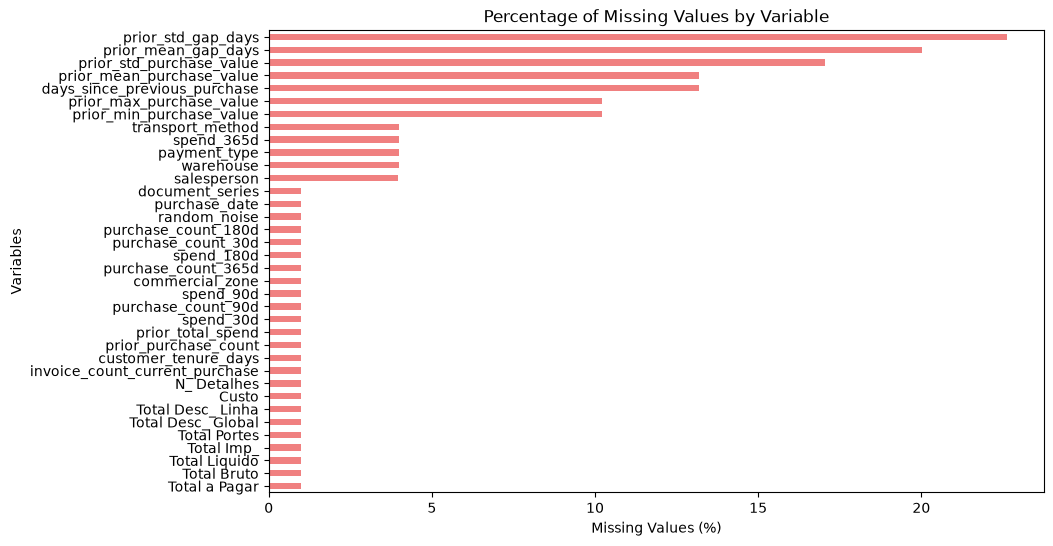

In [6]:
plt.figure(figsize=(10, 6))

missing_values["Percentage (%)"].sort_values().plot(
    kind="barh",
    color="lightcoral"
)

plt.title("Percentage of Missing Values by Variable")
plt.xlabel("Missing Values (%)")
plt.ylabel("Variables")
plt.show()

#### 2.5.3 Missing Values per Observation
We also check how missing values are distributed across observations to identify whether some rows have significantly more missing information than others.This is important because some purchases might have almost no information available. We need to identify these observations before deciding whether to keep, fix or remove them.

In [10]:
missing_per_row = train.isnull().sum(axis=1) #default axis=0 (operates column by column)

missing_distribution = missing_per_row.value_counts().sort_index()

missing_distribution = missing_distribution.rename_axis(
    "Number of Missing Values"
).reset_index(name="Number of Observations")

display(missing_distribution.style.hide(axis="index")) #Display the table without the extra index

Number of Missing Values,Number of Observations
0,3929
1,1287
2,190
3,354
4,100
5,6
7,511
8,86
9,6
36,65


#### 2.5.4 Missing Values and Previous Purchases

In [11]:
train.groupby("prior_purchase_count")["prior_std_purchase_value"].apply(
    lambda x: x.isnull().mean() * 100
).head(10)

prior_purchase_count
0.0    100.0
1.0    100.0
2.0      0.0
3.0      0.0
4.0      0.0
5.0      0.0
6.0      0.0
7.0      0.0
8.0      0.0
9.0      0.0
Name: prior_std_purchase_value, dtype: float64

-0 previous purchases → 100% missing: There's no purchase history to calculate a standard deviation. <br>
-1 previous purchase → 100% missing: One purchase isn't enough to calculate a sample standard deviation.<br>
-2 or more previous purchases → 0% missing: There's enough information to calculate it.

#### 2.5.5 - Observations with Many Missing Values

In [12]:
train.loc[missing_per_row >= 30].head() #shows the rows with 30 or more NaN values

,Total a Pagar,Total Bruto,Total Liquido,Total Imp_,Total Portes,Total Desc_ Global,Total Desc_ Linha,Custo,N_ Detalhes,invoice_count_current_purchase,...,customer_id,payment_type,salesperson,commercial_zone,transport_method,warehouse,document_series,purchase_date,ID,random_noise
393,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,755628,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10000457,NaN
484,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,755628,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10000560,NaN
582,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,427118,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10000678,NaN
583,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,508217,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10000679,NaN
748,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,427118,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10000870,NaN


#### Main Findings
The analysis shows that several variables contain missing values, particularly those related to previous purchasing behaviour.

We found that missing values in `prior_std_purchase_value` are related to customers having fewer than two previous purchases, suggesting that some missing values are expected rather than data errors.

We also identified 65 observations with 36 missing values each. These observations have very little information available and will need further investigation during preprocessing before deciding how to handle them.

### 2.6 Duplicate Observations

We check for duplicate observations to identify any repeated records that could affect our analysis and model performance.

In [13]:
train.duplicated().sum()

np.int64(0)

0 completely identical rows in your dataset. Next we check if there is same IDs

In [14]:
train["ID"].duplicated().sum()

np.int64(0)

No duplicated rows or repeated IDs were found in the training dataset. Since each ID represents a unique purchase observation, no duplicates need to be removed.

### 2.7 Data Inconsistencies and Anomalous Values

We now look for unusual or potentially incorrect values in the dataset, such as negative values where they are not expected or extremely large observations.

This helps us identify possible data quality issues that may need to be addressed during preprocessing.
Let's start by examining the minimum and maximum of each numerical variable

#### 2.7.1 - Minimum and Maximum Values

In [19]:
numerical = train.select_dtypes(include="number")

min_max = numerical.agg(["min", "max"]).T

display(min_max.style.format("{:,.2f}"))

,min,max
Total a Pagar,0.93,"22,297.21"
Total Bruto,0.83,"21,578.28"
Total Liquido,0.76,"18,127.81"
Total Imp_,0.00,"4,169.40"
Total Portes,0.00,181.06
Total Desc_ Global,0.00,218.49
Total Desc_ Linha,0.00,"4,103.44"
Custo,0.00,"7,427.40"
N_ Detalhes,1.00,423.00
invoice_count_current_purchase,1.00,5.00


The minimum and maximum values reveal some potentially suspicious observations:

- **Negative time intervals:** `days_since_previous_purchase` and `prior_mean_gap_days` have minimum values of -4, which is unexpected since the time between purchases should not be negative.
- **Negative monetary values:** `prior_mean_purchase_value` (-2,478.66) and `spend_365d` (-159,115.20) contain negative values, which could indicate errors, refunds or accounting adjustments.
- **Extremely large values:** `prior_mean_purchase_value` and `spend_365d` reach 1,000,000,000, which seems unrealistic compared to typical purchase amounts.
- **High purchase counts:** `prior_purchase_count` reaches 276. Although this is relatively high, it may be reasonable for frequent customers.

These values require further investigation to determine whether they are data errors or legitimate observations before deciding how to handle them during preprocessing.

#### 2.7.2 - Check Negative Values

In [17]:
variables = [
    "days_since_previous_purchase",
    "prior_mean_gap_days",
    "prior_mean_purchase_value",
    "spend_365d"
]

(train[variables] < 0).sum()

days_since_previous_purchase    16
prior_mean_gap_days             16
prior_mean_purchase_value       16
spend_365d                      15
dtype: int64

We found a small number of negative values in four variables. These values seem unusual, especially for the time between purchases, and may indicate data errors.

#### 2.7.3 - Check Extremely Large Values

In [18]:
variables = [
    "prior_mean_purchase_value",
    "spend_365d"
]

train[variables].sort_values(
    by="spend_365d",
    ascending=False
).head(10)

,prior_mean_purchase_value,spend_365d
3514,615.926667,1.000000e+09
2356,870.590000,1.000000e+09
2369,2114.369286,1.000000e+09
4155,1196.175094,1.000000e+09
4395,977.420000,1.000000e+09
1630,NaN,1.000000e+09
3324,154.767826,1.000000e+09
1029,902.712018,1.000000e+09
5851,1801.632857,1.000000e+09
2590,828.988529,1.000000e+09


Some customers have a `spend_365d` value of 1 billion, even though their average previous purchases are much smaller. These values seem unrealistic and may be data errors.

### 2.8 Numerical and Categorical Distributions

We now explore the distributions of some numerical and categorical variables to better understand customer purchasing behaviour. We use histograms, boxplots and countplots to identify patterns, differences and possible outliers.

#### 2.8.1 Numerical Distributions

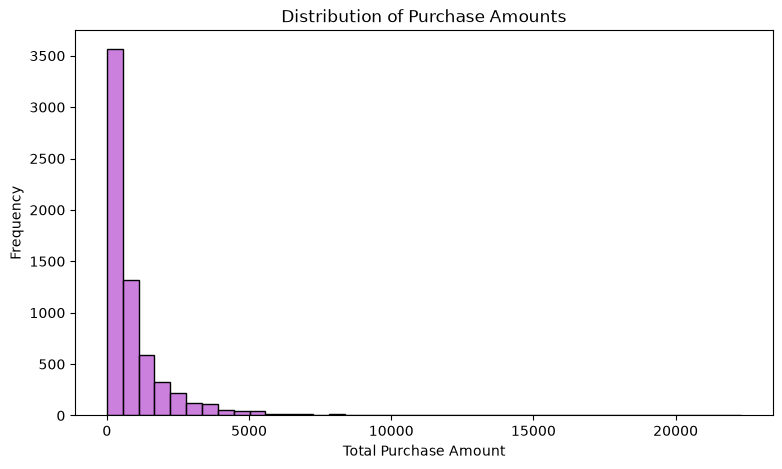

In [26]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=train,
    x="Total a Pagar",
    bins=40,
    color="mediumorchid"
)

plt.title("Distribution of Purchase Amounts")
plt.xlabel("Total Purchase Amount")
plt.ylabel("Frequency")
plt.show()

Most purchases have relatively low amounts, while a smaller number have much higher values. This creates a right-skewed distribution, suggesting that some purchases are considerably larger than others. This is useful because the amount a customer spends might be related to whether they purchase again within 90 days.

#### 2.8.2 Distribution of Previous Purchases

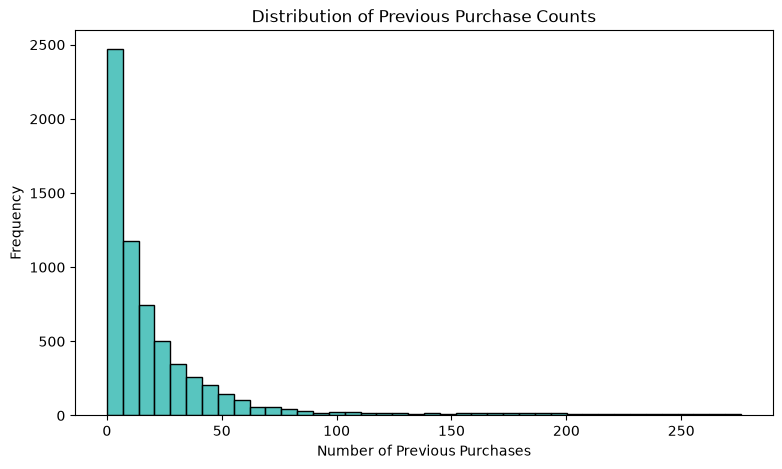

In [22]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=train,
    x="prior_purchase_count",
    bins=40,
    color="lightseagreen"
)

plt.title("Distribution of Previous Purchase Counts")
plt.xlabel("Number of Previous Purchases")
plt.ylabel("Frequency")
plt.show()

Most observations are associated with customers who have made relatively few previous purchases, while a smaller number have a much longer purchasing history. This suggests that purchasing frequency varies considerably between customers. This is useful because a customer's previous purchasing behaviour could be an important predictor of whether they will purchase again.

#### 2.3 Boxplot of Purchase Amounts

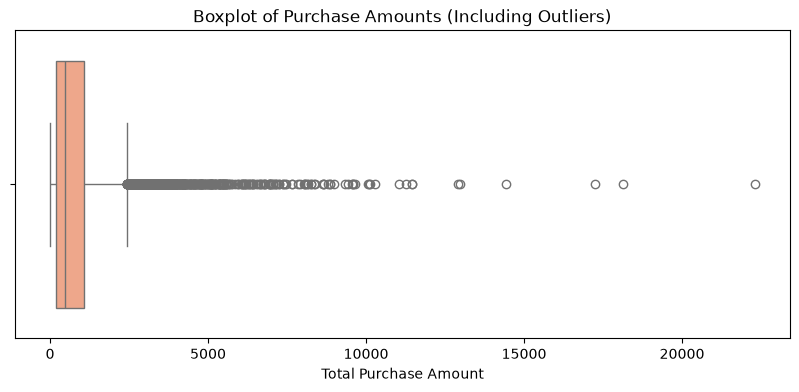

In [28]:
plt.figure(figsize=(10, 4))

sns.boxplot(
    data=train,
    x="Total a Pagar",
    color="lightsalmon"
)

plt.title("Boxplot of Purchase Amounts (Including Outliers)")
plt.xlabel("Total Purchase Amount")
plt.show()

Most purchases have relatively low amounts, but there are several much larger purchases, with some reaching over 20,000. These appear as outliers in the boxplot and show that purchase amounts vary considerably.

#### 2.8.4 Distribution of Payment Types

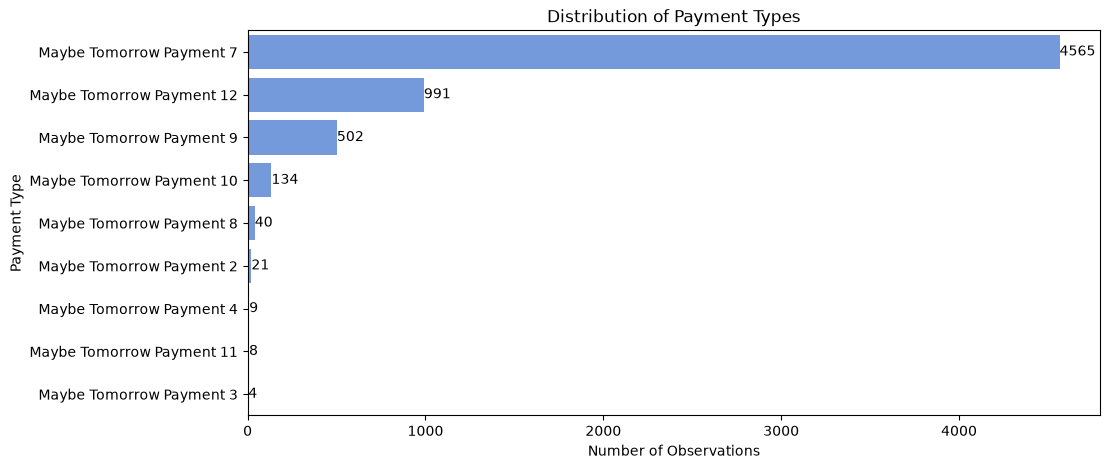

In [29]:
plt.figure(figsize=(11, 5))

ax = sns.countplot(
    data=train,
    y="payment_type",
    order=train["payment_type"].value_counts().index,
    color="cornflowerblue"
)

plt.title("Distribution of Payment Types")
plt.xlabel("Number of Observations")
plt.ylabel("Payment Type")

for container in ax.containers:
    ax.bar_label(container)

plt.show()

Payment Type 7 is by far the most common, followed by Payment Types 12 and 9. The remaining categories are much less frequent, showing that payment types are not equally distributed in the dataset.

### 2.9 Relationships With the Target and Correlations

We now explore how different variables are related to `repeat_purchase_90d`. The goal is to identify patterns that may help predict whether a customer will make another purchase within 90 days.

We also examine correlations between numerical variables to identify possible relationships and similarities between features.

#### 2.9.1 Traget Variable Distribution
Before exploring relationships, let's check how many observations belong to each target class.

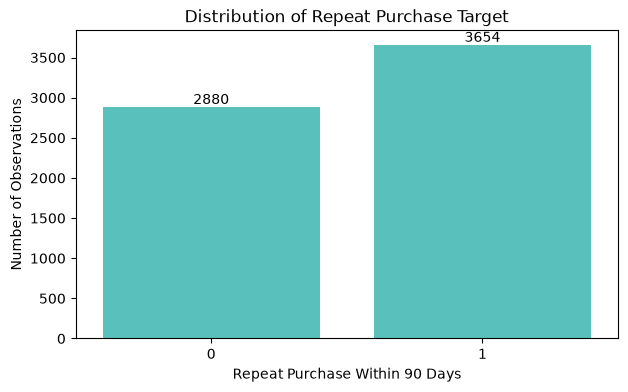

In [30]:
plt.figure(figsize=(7, 4))

ax = sns.countplot(
    data=train,
    x="repeat_purchase_90d",
    color="mediumturquoise"
)

plt.title("Distribution of Repeat Purchase Target")
plt.xlabel("Repeat Purchase Within 90 Days")
plt.ylabel("Number of Observations")

for container in ax.containers:
    ax.bar_label(container)

plt.show()

The target variable is fairly balanced, with slightly more observations belonging to class 1 than class 0. This means that repeat purchases within 90 days are somewhat more common in the training data.

#### 2.9.2 Previous Purchases vs. Repeat Purchase

In [31]:
train.groupby("repeat_purchase_90d")["prior_purchase_count"].median()

repeat_purchase_90d
0     6.0
1    17.0
Name: prior_purchase_count, dtype: float64

Customers who purchase again within 90 days tend to have more previous purchases. The median is 17 for customers who return, compared to 6 for those who don't. This suggests that purchasing history may be useful for prediction.

#### 2.9.3 Correlations with the Target

In [32]:
variables = [
    "Total a Pagar",
    "prior_purchase_count",
    "days_since_previous_purchase",
    "purchase_count_90d",
    "repeat_purchase_90d"
]

correlations = train[variables].corr()

correlations["repeat_purchase_90d"].sort_values(
    ascending=False
)

repeat_purchase_90d             1.000000
purchase_count_90d              0.327921
prior_purchase_count            0.298811
Total a Pagar                   0.077731
days_since_previous_purchase   -0.195541
Name: repeat_purchase_90d, dtype: float64

The correlation results suggest that previous purchasing activity is related to repeat purchases. `purchase_count_90d` and `prior_purchase_count` show positive correlations with the target, while `days_since_previous_purchase` has a negative correlation. The current purchase amount shows a much weaker relationship.

#### 2.9.4 Spearman Correlation Heatmap

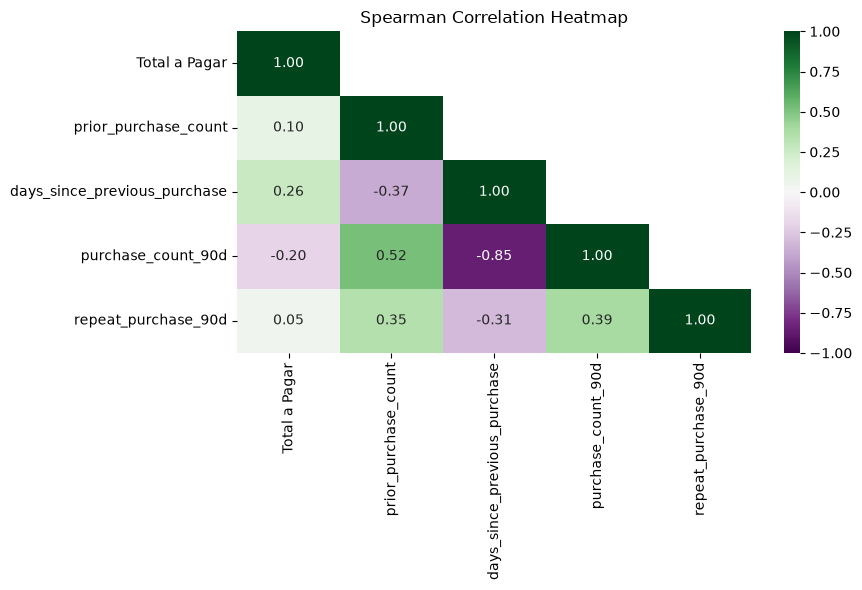

In [37]:
mask = np.triu(np.ones_like(correlations, dtype=bool), k=1)

plt.figure(figsize=(9, 6))

sns.heatmap(
    correlations,
    mask=mask,
    annot=True,
    cmap="PRGn",
    fmt=".2f",
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Spearman Correlation Heatmap")
plt.tight_layout()
plt.show()

In [ ]:
The results suggest that previous purchasing behaviour is related to whether customers purchase again within 90 days. Variables such as `prior_purchase_count` and `purchase_count_90d` show positive correlations with the target, while `days_since_previous_purchase` shows a negative correlation.

The heatmap also helps us identify relationships between the predictors, which may be useful later during feature selection.

#### 2.9.5 Payment Type vs Repeat Purchase
We now explore the relationship between `payment_type` and our target variable to see whether repeat-purchase rates differ between payment categories.

In [38]:
repeat_rate = (
    train.groupby("payment_type", dropna=False)["repeat_purchase_90d"]
    .mean()
    .sort_values(ascending=False) * 100
)

repeat_rate

payment_type
Maybe Tomorrow Payment 9     95.019920
Maybe Tomorrow Payment 11    62.500000
NaN                          55.000000
Maybe Tomorrow Payment 12    54.288597
Maybe Tomorrow Payment 7     52.727273
Maybe Tomorrow Payment 2     52.380952
Maybe Tomorrow Payment 3     50.000000
Maybe Tomorrow Payment 4     44.444444
Maybe Tomorrow Payment 10    40.298507
Maybe Tomorrow Payment 8     32.500000
Name: repeat_purchase_90d, dtype: float64

Repeat-purchase rates vary between payment types. Payment 9 has the highest rate (95%), while Payment 8 has the lowest (32.5%). This suggests that payment type may be useful for predicting repeat purchases. However, some categories have few observations, so their results should be interpreted carefully.

### 2.10 Summary of EDA Findings

### 2.10 Summary of EDA Findings

Our exploratory analysis revealed several important findings:

- **Missing values:** Some variables have missing values, particularly those related to previous purchasing history. We also identified 65 observations with very little information available.
- **Data inconsistencies:** We found negative time intervals and suspicious monetary values, including extremely large values of 1 billion.
- **Distributions:** Purchase amounts and previous purchase counts are right-skewed, with most observations having relatively low values and a smaller number having much higher values.
- **Repeat purchasing behaviour:** Customers who purchase again within 90 days tend to have more previous purchases and more recent purchasing activity.
- **Correlations:** The Spearman analysis suggests that previous purchasing frequency and recency are related to repeat purchases.
- **Payment types:** Repeat-purchase rates vary considerably between payment categories, suggesting that payment type may be useful for prediction.

These findings will help us decide how to clean and prepare the data and which variables to investigate further during feature selection.